In [278]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, make_scorer

In [279]:
df_full = pd.read_parquet("../data/processed_full.parquet")
df_full = (
    df_full
        .sample(frac=1, random_state=42)   # shuffle rows
        .reset_index(drop=True)            # clean new index
)

In [280]:
df_full.index.value_counts()

739    1
0      1
1      1
2      1
700    1
      ..
7      1
8      1
9      1
10     1
11     1
Name: count, Length: 740, dtype: int64

In [281]:
df = df_full.copy()

In [282]:
# Targets
df["y_bin"]   = (df["num"] > 0).astype(int)
df["y_multi"] = df["num"].astype(int)
df = df.drop(columns=["num", "target"])

In [283]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,origin,y_bin,y_multi
0,48.0,1.0,4.0,130.0,256.0,1.0,2.0,150.0,1.0,0.0,CLE,1,3
1,53.0,0.0,2.0,140.0,216.0,0.0,0.0,142.0,1.0,2.0,HUN,0,0
2,39.0,1.0,2.0,190.0,241.0,0.0,0.0,106.0,0.0,0.0,HUN,0,0
3,42.0,0.0,3.0,115.0,211.0,0.0,1.0,137.0,0.0,0.0,HUN,0,0
4,52.0,1.0,2.0,120.0,284.0,0.0,0.0,118.0,0.0,0.0,HUN,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,67.0,1.0,4.0,125.0,254.0,1.0,0.0,163.0,0.0,0.2,CLE,1,3
736,59.0,1.0,4.0,140.0,177.0,0.0,0.0,162.0,1.0,0.0,CLE,1,2
737,61.0,1.0,4.0,140.0,207.0,0.0,2.0,138.0,1.0,1.9,CLE,1,1
738,54.0,1.0,3.0,120.0,217.0,0.0,0.0,137.0,0.0,0.0,HUN,0,0


In [284]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "origin"]
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]


In [285]:
# One-hot encode categoricals
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True)
df_enc

,age,trestbps,chol,thalach,oldpeak,y_bin,y_multi,sex_1.0,cp_2.0,cp_3.0,cp_4.0,fbs_1.0,restecg_1.0,restecg_2.0,exang_1.0,origin_HUN,origin_SW,origin_VA
0,48.0,130.0,256.0,150.0,0.0,1,3,True,False,False,True,True,False,True,True,False,False,False
1,53.0,140.0,216.0,142.0,2.0,0,0,False,True,False,False,False,False,False,True,True,False,False
2,39.0,190.0,241.0,106.0,0.0,0,0,True,True,False,False,False,False,False,False,True,False,False
3,42.0,115.0,211.0,137.0,0.0,0,0,False,False,True,False,False,True,False,False,True,False,False
4,52.0,120.0,284.0,118.0,0.0,0,0,True,True,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,67.0,125.0,254.0,163.0,0.2,1,3,True,False,False,True,True,False,False,False,False,False,False
736,59.0,140.0,177.0,162.0,0.0,1,2,True,False,False,True,False,False,False,True,False,False,False
737,61.0,140.0,207.0,138.0,1.9,1,1,True,False,False,True,False,False,True,True,False,False,False
738,54.0,120.0,217.0,137.0,0.0,0,0,True,False,True,False,False,False,False,False,True,False,False


In [286]:
X = df_enc.drop(columns=[ "y_bin", "y_multi"])
y_bin = df_enc["y_bin"].values
y_multi = df_enc["y_multi"].values

In [287]:
# Sanity checks
print("X shape:", X.shape)
print("y_bin distribution:\n", pd.Series(y_bin).value_counts())
print("y_multi distribution:\n", pd.Series(y_multi).value_counts().sort_index())
print("Any NA in X?", X.isna().any().any())

X shape: (740, 16)
y_bin distribution:
 1    383
0    357
Name: count, dtype: int64
y_multi distribution:
 0    357
1    204
2     79
3     78
4     22
Name: count, dtype: int64
Any NA in X? False


In [288]:
# Standardise continuous predictors
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[num_cols] = scaler.fit_transform(X[num_cols])
X_scaled

,age,trestbps,chol,thalach,oldpeak,sex_1.0,cp_2.0,cp_3.0,cp_4.0,fbs_1.0,restecg_1.0,restecg_2.0,exang_1.0,origin_HUN,origin_SW,origin_VA
0,-0.542164,-0.148317,0.383357,0.435773,-0.823181,True,False,False,True,True,False,True,True,False,False,False
1,-0.010349,0.390224,-0.044216,0.126039,1.017719,False,True,False,False,False,False,False,True,True,False,False
2,-1.499431,3.082929,0.223017,-1.267764,-0.823181,True,True,False,False,False,False,False,False,True,False,False
3,-1.180342,-0.956128,-0.097663,-0.067545,-0.823181,False,False,True,False,False,True,False,False,True,False,False
4,-0.116712,-0.686858,0.682658,-0.803163,-0.823181,True,True,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,1.478733,-0.417588,0.361978,0.939091,-0.639091,True,False,False,True,True,False,False,False,False,False,False
736,0.627829,0.390224,-0.461100,0.900374,-0.823181,True,False,False,True,False,False,False,True,False,False,False
737,0.840555,0.390224,-0.140420,-0.028828,0.925674,True,False,False,True,False,False,True,True,False,False,False
738,0.096014,-0.686858,-0.033527,-0.067545,-0.823181,True,False,True,False,False,False,False,False,True,False,False


In [289]:
# Add an intercept
X_sm = sm.add_constant(X_scaled, has_constant="add")


X_sm.dtypes

const          float64
age            float64
trestbps       float64
chol           float64
thalach        float64
oldpeak        float64
sex_1.0           bool
cp_2.0            bool
cp_3.0            bool
cp_4.0            bool
fbs_1.0           bool
restecg_1.0       bool
restecg_2.0       bool
exang_1.0         bool
origin_HUN        bool
origin_SW         bool
origin_VA         bool
dtype: object

In [290]:
# # convert bools to float
X_sm = X_sm.astype(float)
X_sm.dtypes

const          float64
age            float64
trestbps       float64
chol           float64
thalach        float64
oldpeak        float64
sex_1.0        float64
cp_2.0         float64
cp_3.0         float64
cp_4.0         float64
fbs_1.0        float64
restecg_1.0    float64
restecg_2.0    float64
exang_1.0      float64
origin_HUN     float64
origin_SW      float64
origin_VA      float64
dtype: object

In [291]:
X_sm

,const,age,trestbps,chol,thalach,oldpeak,sex_1.0,cp_2.0,cp_3.0,cp_4.0,fbs_1.0,restecg_1.0,restecg_2.0,exang_1.0,origin_HUN,origin_SW,origin_VA
0,1.0,-0.542164,-0.148317,0.383357,0.435773,-0.823181,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
1,1.0,-0.010349,0.390224,-0.044216,0.126039,1.017719,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2,1.0,-1.499431,3.082929,0.223017,-1.267764,-0.823181,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.0,-1.180342,-0.956128,-0.097663,-0.067545,-0.823181,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,1.0,-0.116712,-0.686858,0.682658,-0.803163,-0.823181,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,1.0,1.478733,-0.417588,0.361978,0.939091,-0.639091,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
736,1.0,0.627829,0.390224,-0.461100,0.900374,-0.823181,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
737,1.0,0.840555,0.390224,-0.140420,-0.028828,0.925674,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
738,1.0,0.096014,-0.686858,-0.033527,-0.067545,-0.823181,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [292]:
# Fit the pure MLE models
logit_model = sm.Logit(y_bin, X_sm)
logit_res = logit_model.fit(disp=False)
print(logit_res.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  740
Model:                          Logit   Df Residuals:                      723
Method:                           MLE   Df Model:                           16
Date:                Wed, 25 Feb 2026   Pseudo R-squ.:                  0.4275
Time:                        07:18:24   Log-Likelihood:                -293.39
converged:                       True   LL-Null:                       -512.47
Covariance Type:            nonrobust   LLR p-value:                 3.529e-83
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -2.3567      0.517     -4.559      0.000      -3.370      -1.343
age             0.1791      0.133      1.350      0.177      -0.081       0.439
trestbps        0.0759      0.112      0.674    

In [293]:
logit_res.params

const         -2.356709
age            0.179074
trestbps       0.075858
chol           0.258876
thalach       -0.240625
oldpeak        0.793397
sex_1.0        1.368765
cp_2.0        -0.352862
cp_3.0        -0.020948
cp_4.0         1.422291
fbs_1.0        0.541030
restecg_1.0   -0.156224
restecg_2.0    0.240401
exang_1.0      0.992966
origin_HUN     0.001538
origin_SW      4.614863
origin_VA      0.537649
dtype: float64

In [294]:
mnlogit_model = sm.MNLogit(y_multi, X_sm)
mnlogit_res = mnlogit_model.fit(method="bfgs", maxiter=500, disp=False)
print(mnlogit_res.summary())

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                  740
Model:                        MNLogit   Df Residuals:                      672
Method:                           MLE   Df Model:                           64
Date:                Wed, 25 Feb 2026   Pseudo R-squ.:                  0.3527
Time:                        07:18:24   Log-Likelihood:                -616.70
converged:                       True   LL-Null:                       -952.66
Covariance Type:            nonrobust   LLR p-value:                3.438e-102
        y=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -2.7277      0.567     -4.813      0.000      -3.838      -1.617
age             0.0868      0.141      0.614      0.539      -0.190       0.364
trestbps        0.0689      0.120      0.573    

In [295]:
n = X_sm.shape[0]

def model_stats(res, model_name: str):
    ll = float(res.llf)                 # maximised log-likelihood
    k  = int(res.df_model) + 1          # number of estimated parameters (+ intercept)
    bic = -2 * ll + k * np.log(n)
    aic = -2 * ll + 2 * k               # optional, often useful to report alongside BIC
    ll_per_obs = ll / n
    neg_ll_per_obs = -ll_per_obs        # equals in-sample log-loss (average)
    return {
        "model": model_name,
        "n": n,
        "k_params": k,
        "logLik": ll,
        "logLik_per_obs": ll_per_obs,
        "in_sample_logloss": neg_ll_per_obs,
        "AIC": aic,
        "BIC": bic,
        "converged": getattr(res, "mle_retvals", {}).get("converged", None),
    }

stats_bin   = model_stats(logit_res, "Binary Logit (MLE)")
stats_multi = model_stats(mnlogit_res, "Multinomial Logit (MLE)")

summary_df = pd.DataFrame([stats_bin, stats_multi]).set_index("model")
print(summary_df[["n","k_params","logLik","logLik_per_obs","in_sample_logloss","AIC","BIC","converged"]])

# --- Likelihood ratio style statistic vs null is available for binary logit ---
# (This is already shown in your summary, but this prints it cleanly)
if hasattr(logit_res, "llnull") and logit_res.llnull is not None:
    ll_null = float(logit_res.llnull)
    lr_stat = 2 * (float(logit_res.llf) - ll_null)
    print("\nBinary Logit: LL-Null =", ll_null, " LR stat =", lr_stat)

                           n  k_params      logLik  logLik_per_obs  \
model                                                                
Binary Logit (MLE)       740        17 -293.385197       -0.396466   
Multinomial Logit (MLE)  740        65 -616.700465       -0.833379   

                         in_sample_logloss          AIC          BIC  \
model                                                                  
Binary Logit (MLE)                0.396466   620.770393   699.083446   
Multinomial Logit (MLE)           0.833379  1363.400930  1662.833192   

                         converged  
model                               
Binary Logit (MLE)            True  
Multinomial Logit (MLE)       True  

Binary Logit: LL-Null = -512.4720628514848  LR stat = 438.17373255058305


In [296]:
print(np.abs(mnlogit_res.params).max())
mnlogit_res.params

0     4.223267
1    19.564138
2    20.053639
3    24.561248
dtype: float64


,0,1,2,3
const,-2.727709,-4.280145,-5.132850,-8.617322
age,0.086820,0.351204,0.460372,0.361180
trestbps,0.068877,0.105756,-0.006190,0.407300
chol,0.260473,0.310133,0.262146,0.486268
thalach,-0.172407,-0.359583,-0.645285,-0.317989
oldpeak,0.592041,1.034760,1.272850,1.711683
sex_1.0,1.230319,1.836283,1.435486,2.951194
cp_2.0,-0.590499,-0.261462,0.698587,-9.003810
cp_3.0,-0.207948,0.050288,0.612278,0.549825
cp_4.0,1.170965,1.902700,1.897394,2.599206


In [297]:
# Origin_HUN has no observations for class 2,3,4
pd.crosstab(df_full["origin"], df_full["num"])

num,0,1,2,3,4
origin,,,,,
CLE,164,55,36,35,13
HUN,163,98,0,0,0
SW,1,12,14,16,3
VA,29,39,29,27,6


In [298]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,origin,y_bin,y_multi
0,48.0,1.0,4.0,130.0,256.0,1.0,2.0,150.0,1.0,0.0,CLE,1,3
1,53.0,0.0,2.0,140.0,216.0,0.0,0.0,142.0,1.0,2.0,HUN,0,0
2,39.0,1.0,2.0,190.0,241.0,0.0,0.0,106.0,0.0,0.0,HUN,0,0
3,42.0,0.0,3.0,115.0,211.0,0.0,1.0,137.0,0.0,0.0,HUN,0,0
4,52.0,1.0,2.0,120.0,284.0,0.0,0.0,118.0,0.0,0.0,HUN,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,67.0,1.0,4.0,125.0,254.0,1.0,0.0,163.0,0.0,0.2,CLE,1,3
736,59.0,1.0,4.0,140.0,177.0,0.0,0.0,162.0,1.0,0.0,CLE,1,2
737,61.0,1.0,4.0,140.0,207.0,0.0,2.0,138.0,1.0,1.9,CLE,1,1
738,54.0,1.0,3.0,120.0,217.0,0.0,0.0,137.0,0.0,0.0,HUN,0,0


In [299]:
# reconstruct df
df_no_origin = df.drop(columns=["origin"]).copy()

cat_cols = ["sex", "cp", "fbs", "restecg", "exang"]
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

df_enc = pd.get_dummies(df_no_origin, columns=cat_cols, drop_first=True)

X = df_enc.drop(columns=[ "y_bin", "y_multi"])
y_bin = df_enc["y_bin"].values
y_multi = df_enc["y_multi"].values

scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[num_cols] = scaler.fit_transform(X[num_cols])

X_sm = sm.add_constant(X_scaled, has_constant="add").astype(float)
X_sm


,const,age,trestbps,chol,thalach,oldpeak,sex_1.0,cp_2.0,cp_3.0,cp_4.0,fbs_1.0,restecg_1.0,restecg_2.0,exang_1.0
0,1.0,-0.542164,-0.148317,0.383357,0.435773,-0.823181,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
1,1.0,-0.010349,0.390224,-0.044216,0.126039,1.017719,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.0,-1.499431,3.082929,0.223017,-1.267764,-0.823181,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,-1.180342,-0.956128,-0.097663,-0.067545,-0.823181,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,1.0,-0.116712,-0.686858,0.682658,-0.803163,-0.823181,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,1.0,1.478733,-0.417588,0.361978,0.939091,-0.639091,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
736,1.0,0.627829,0.390224,-0.461100,0.900374,-0.823181,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
737,1.0,0.840555,0.390224,-0.140420,-0.028828,0.925674,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
738,1.0,0.096014,-0.686858,-0.033527,-0.067545,-0.823181,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [300]:
# Fit the pure MLE models
logit_model = sm.Logit(y_bin, X_sm)
logit_res = logit_model.fit(disp=False)
print(logit_res.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  740
Model:                          Logit   Df Residuals:                      726
Method:                           MLE   Df Model:                           13
Date:                Wed, 25 Feb 2026   Pseudo R-squ.:                  0.3933
Time:                        07:18:25   Log-Likelihood:                -310.89
converged:                       True   LL-Null:                       -512.47
Covariance Type:            nonrobust   LLR p-value:                 4.810e-78
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -2.0561      0.476     -4.319      0.000      -2.989      -1.123
age             0.2005      0.119      1.690      0.091      -0.032       0.433
trestbps        0.1145      0.106      1.077    

In [301]:
# ridge_bin.fit(X_ridge_np, y_bin_np)

# ridge_bin_coef = ridge_bin.coef_.ravel()

logit_res.params

const         -2.056124
age            0.200538
trestbps       0.114464
chol          -0.181738
thalach       -0.361830
oldpeak        0.682858
sex_1.0        1.299613
cp_2.0        -0.418834
cp_3.0        -0.014581
cp_4.0         1.431577
fbs_1.0        0.526597
restecg_1.0   -0.078208
restecg_2.0    0.256040
exang_1.0      1.008121
dtype: float64

In [302]:
mnlogit_model = sm.MNLogit(y_multi, X_sm)
mnlogit_res = mnlogit_model.fit(method="bfgs", maxiter=500, disp=False)
print(mnlogit_res.summary())

                          MNLogit Regression Results                          
Dep. Variable:                      y   No. Observations:                  740
Model:                        MNLogit   Df Residuals:                      684
Method:                           MLE   Df Model:                           52
Date:                Wed, 25 Feb 2026   Pseudo R-squ.:                  0.2774
Time:                        07:18:25   Log-Likelihood:                -688.38
converged:                       True   LL-Null:                       -952.66
Covariance Type:            nonrobust   LLR p-value:                 4.267e-80
        y=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -2.2522      0.528     -4.264      0.000      -3.287      -1.217
age            -0.0175      0.128     -0.137      0.891      -0.268       0.233
trestbps        0.1420      0.115      1.235    

In [303]:
n = X_sm.shape[0]

def model_stats(res, model_name: str):
    ll = float(res.llf)                 # maximised log-likelihood
    k  = int(res.df_model) + 1          # number of estimated parameters (+ intercept)
    bic = -2 * ll + k * np.log(n)
    aic = -2 * ll + 2 * k               # optional, often useful to report alongside BIC
    ll_per_obs = ll / n
    neg_ll_per_obs = -ll_per_obs        # equals in-sample log-loss (average)
    return {
        "model": model_name,
        "n": n,
        "k_params": k,
        "logLik": ll,
        "logLik_per_obs": ll_per_obs,
        "in_sample_logloss": neg_ll_per_obs,
        "AIC": aic,
        "BIC": bic,
        "converged": getattr(res, "mle_retvals", {}).get("converged", None),
    }

stats_bin   = model_stats(logit_res, "Binary Logit (MLE)")
stats_multi = model_stats(mnlogit_res, "Multinomial Logit (MLE)")

summary_df = pd.DataFrame([stats_bin, stats_multi]).set_index("model")
print(summary_df[["n","k_params","logLik","logLik_per_obs","in_sample_logloss","AIC","BIC","converged"]])

# --- Likelihood ratio style statistic vs null is available for binary logit ---
# (This is already shown in your summary, but this prints it cleanly)
if hasattr(logit_res, "llnull") and logit_res.llnull is not None:
    ll_null = float(logit_res.llnull)
    lr_stat = 2 * (float(logit_res.llf) - ll_null)
    print("\nBinary Logit: LL-Null =", ll_null, " LR stat =", lr_stat)

                           n  k_params      logLik  logLik_per_obs  \
model                                                                
Binary Logit (MLE)       740        14 -310.892161       -0.420125   
Multinomial Logit (MLE)  740        53 -688.384268       -0.930249   

                         in_sample_logloss          AIC          BIC  \
model                                                                  
Binary Logit (MLE)                0.420125   649.784323   714.277425   
Multinomial Logit (MLE)           0.930249  1482.768537  1726.920997   

                         converged  
model                               
Binary Logit (MLE)            True  
Multinomial Logit (MLE)       True  

Binary Logit: LL-Null = -512.4720628514848  LR stat = 403.1598031103397


In [304]:
print(np.abs(mnlogit_res.params).max())
mnlogit_res.params

0    2.252213
1    4.301033
2    4.972605
3    8.817206
dtype: float64


,0,1,2,3
const,-2.252213,-4.301033,-4.972605,-7.816613
age,-0.017493,0.663294,0.731872,0.706930
trestbps,0.141974,0.061669,-0.016010,0.366805
chol,0.002511,-0.451423,-0.568468,-0.535096
thalach,-0.345086,-0.278901,-0.587938,-0.276212
oldpeak,0.503036,0.839267,1.039844,1.411210
sex_1.0,1.243670,1.462804,1.054330,2.326449
cp_2.0,-0.502319,-0.759605,0.051674,-8.817206
cp_3.0,-0.173164,0.011644,0.516456,0.245352
cp_4.0,1.204421,1.777474,1.802390,2.404319


In [305]:
df = df_full.copy()

# Targets
y_bin = (df["num"] > 0).astype(int).values
y_multi = df["num"].astype(int).values

# Predictors (drop target and origin)
X_df = df.drop(columns=["num", "origin"])

# Categorical vs numeric
cat_cols = ["sex", "cp", "fbs", "restecg", "exang"]
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

# Preprocess: scale numeric, one-hot categorical (drop first to avoid collinearity)
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop",
)

### MLE Cross validation

In [306]:
bin_clf = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    max_iter=5000,
)

bin_pipe = Pipeline([
    ("prep", preprocess),
    ("model", bin_clf),
])

# Grid over C (inverse regularization strength)
C_grid = np.logspace(-3, 3, 25)

# Use log-loss; GridSearchCV maximizes score, so use negative log loss
cv_bin = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

bin_search = GridSearchCV(
    bin_pipe,
    param_grid={"model__C": C_grid},
    scoring="neg_log_loss",
    cv=cv_bin,
    n_jobs=-1,
)

bin_search.fit(X_df, y_bin)

print("Binary Ridge best C:", bin_search.best_params_["model__C"])
print("Binary Ridge best CV log-loss:", -bin_search.best_score_)

Binary Ridge best C: 0.31622776601683794
Binary Ridge best CV log-loss: 0.44118556756492333


### Multinomial cross validation

In [307]:
# Ridge multinomial logistic regression
multi_clf = LogisticRegression(
    penalty="l2",
    solver="lbfgs",
    multi_class="multinomial",
    max_iter=8000,
)

multi_pipe = Pipeline([
    ("prep", preprocess),
    ("model", multi_clf),
])

# For multiclass, CV should be stratified too
cv_multi = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

multi_search = GridSearchCV(
    multi_pipe,
    param_grid={"model__C": C_grid},
    scoring="neg_log_loss",
    cv=cv_multi,
    n_jobs=-1,
)

multi_search.fit(X_df, y_multi)

print("Multinomial Ridge best C:", multi_search.best_params_["model__C"])
print("Multinomial Ridge best CV log-loss:", -multi_search.best_score_)

Multinomial Ridge best C: 0.1
Multinomial Ridge best CV log-loss: 0.9996685261305597


C:\Users\abels\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [308]:
# Get fitted models
bin_best = bin_search.best_estimator_
multi_best = multi_search.best_estimator_

# Coefficients are on the processed feature space (after scaling+onehot)
bin_coef = bin_best.named_steps["model"].coef_.ravel()
print("Binary Ridge max |coef|:", np.max(np.abs(bin_coef)))

multi_coef = multi_best.named_steps["model"].coef_   # shape: (n_classes, n_features)
print("Multinomial Ridge max |coef| per class:", np.max(np.abs(multi_coef), axis=1))
print("Multinomial Ridge overall max |coef|:", np.max(np.abs(multi_coef)))

Binary Ridge max |coef|: 1.1407254108744695
Multinomial Ridge max |coef| per class: [0.78845979 0.37325051 0.30563365 0.37997538 0.51001922]
Multinomial Ridge overall max |coef|: 0.7884597856402257


In [309]:
# compare MLE vs Ridge coefficients

# 1) Prepare X for sklearn (no intercept column)
X_ridge = X_sm.drop(columns=["const"])
cols = X_ridge.columns

# 2) Fit ridge logistic with the CV-chosen C
C_best_bin = 0.31622776601683794

ridge_bin = LogisticRegression(
    penalty="l2",
    C=C_best_bin,
    solver="lbfgs",
    max_iter=5000
)
ridge_bin.fit(X_ridge.values, y_bin)

# 3) Put ridge coefficients into a Series aligned to feature names
coef_ridge = pd.Series(ridge_bin.coef_.ravel(), index=cols, name="ridge")

# 4) MLE coefficients aligned (drop intercept)
coef_mle = logit_res.params.drop("const").rename("mle")

# 5) Compare
cmp = pd.concat([coef_mle, coef_ridge], axis=1)
cmp["abs_mle"] = cmp["mle"].abs()
cmp["abs_ridge"] = cmp["ridge"].abs()
cmp["shrink_ratio"] = cmp["abs_ridge"] / cmp["abs_mle"]
cmp.sort_values("abs_mle", ascending=False).head(20)

,mle,ridge,abs_mle,abs_ridge,shrink_ratio
cp_4.0,1.431577,1.140725,1.431577,1.140725,0.796831
sex_1.0,1.299613,1.077615,1.299613,1.077615,0.829182
exang_1.0,1.008121,0.914310,1.008121,0.914310,0.906945
oldpeak,0.682858,0.658691,0.682858,0.658691,0.964609
fbs_1.0,0.526597,0.415734,0.526597,0.415734,0.789474
cp_2.0,-0.418834,-0.547914,0.418834,0.547914,1.308188
thalach,-0.361830,-0.372541,0.361830,0.372541,1.029605
restecg_2.0,0.256040,0.208379,0.256040,0.208379,0.813854
age,0.200538,0.197988,0.200538,0.197988,0.987280
chol,-0.181738,-0.181630,0.181738,0.181630,0.999401


In [310]:
C_best_multi = 0.1

ridge_multi = LogisticRegression(
    penalty="l2",
    C=C_best_multi,
    solver="lbfgs",
    multi_class="multinomial",
    max_iter=10000
)
ridge_multi.fit(X_ridge.values, y_multi)

# coef_ shape: (n_classes, n_features)
max_abs_per_class = np.max(np.abs(ridge_multi.coef_), axis=1)
overall_max = np.max(np.abs(ridge_multi.coef_))

print("Ridge multinomial max |coef| per class:", max_abs_per_class)
print("Ridge multinomial overall max |coef|:", overall_max)

Ridge multinomial max |coef| per class: [0.78845979 0.37325051 0.30563365 0.37997538 0.51001922]
Ridge multinomial overall max |coef|: 0.7884597856402257


C:\Users\abels\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


# Log-loss

In [311]:


cv_same = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# MLE (no penalty)
mle_bin = LogisticRegression(penalty=None, solver="lbfgs", max_iter=5000)
mle_scores = cross_val_score(mle_bin, X_ridge, y_bin, cv=cv_same, scoring="neg_log_loss")
print("Binary MLE CV log-loss (same folds):", -mle_scores.mean())

# Ridge at best C
ridge_bin = LogisticRegression(penalty="l2", C=0.31622776601683794, solver="lbfgs", max_iter=5000)
ridge_scores = cross_val_score(ridge_bin, X_ridge, y_bin, cv=cv_same, scoring="neg_log_loss")
print("Binary Ridge CV log-loss (same folds):", -ridge_scores.mean())

Binary MLE CV log-loss (same folds): 0.4454326011701057
Binary Ridge CV log-loss (same folds): 0.4411718733302507


In [312]:
cv_multi = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# MLE multinomial
mle_multi = LogisticRegression(
    penalty= None,
    solver="lbfgs",
    max_iter=10000
)

cv_scores_mle_multi = cross_val_score(
    mle_multi,
    X_ridge,
    y_multi,
    cv=cv_multi,
    scoring="neg_log_loss"
)

print("Multinomial MLE CV log-loss:", -cv_scores_mle_multi.mean())


# Ridge multinomial
ridge_multi = LogisticRegression(
    penalty="l2",
    C=0.1,
    solver="lbfgs",
    max_iter=10000
)

cv_scores_ridge_multi = cross_val_score(
    ridge_multi,
    X_ridge,
    y_multi,
    cv=cv_multi,
    scoring="neg_log_loss"
)

print("Multinomial Ridge CV log-loss:", -cv_scores_ridge_multi.mean())


Multinomial MLE CV log-loss: 1.0568420161746082
Multinomial Ridge CV log-loss: 0.9995483159225719


In [313]:
# fit ridge regression on same dataset with CV selected shrinking factor
# Remove intercept column for sklearn
X_ridge = X_sm.drop(columns=["const"])

# Convert to numpy arrays
X_ridge_np = X_ridge.values
y_bin_np = y_bin
y_multi_np = y_multi


ridge_bin = LogisticRegression(
    penalty="l2",
    C=0.31622776601683794,  # your best C
    solver="lbfgs",
    max_iter=5000
)

ridge_bin.fit(X_ridge_np, y_bin_np)

ridge_bin_coef = ridge_bin.coef_.ravel()

ridge_bin_coef_series = pd.Series(
    ridge_bin_coef,
    index=X_ridge.columns,
    name="coef_ridge"
)

ridge_bin_coef_series.abs().sort_values(ascending=False)

cp_4.0         1.140725
sex_1.0        1.077615
exang_1.0      0.914310
oldpeak        0.658691
cp_2.0         0.547914
fbs_1.0        0.415734
thalach        0.372541
restecg_2.0    0.208379
cp_3.0         0.200095
age            0.197988
chol           0.181630
trestbps       0.106161
restecg_1.0    0.032995
Name: coef_ridge, dtype: float64

### Binary ridge: CV log-loss vs C

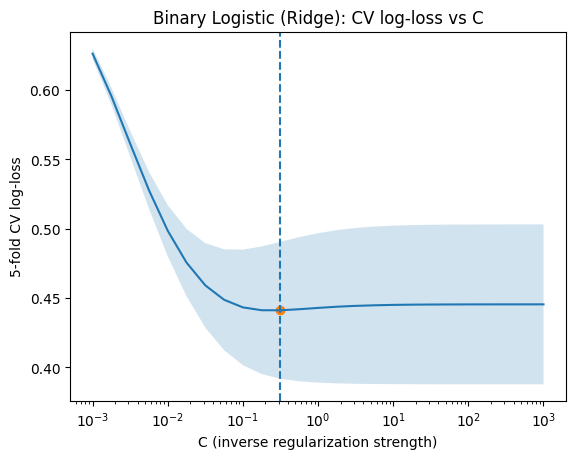

Binary best C: 0.31622776601683794 best CV log-loss: 0.44118556756492333


In [314]:
# --- Binary ---
bin_results = pd.DataFrame(bin_search.cv_results_).copy()
bin_results["C"] = bin_results["param_model__C"].astype(float)
bin_results["mean_logloss"] = -bin_results["mean_test_score"]
bin_results["std_logloss"]  = bin_results["std_test_score"]  # note: std of NEG logloss
bin_results["std_logloss"]  = bin_results["std_logloss"].abs()

bin_results = bin_results.sort_values("C")

best_C_bin = bin_search.best_params_["model__C"]
best_loss_bin = -bin_search.best_score_

plt.figure()
plt.semilogx(bin_results["C"], bin_results["mean_logloss"])
plt.fill_between(
    bin_results["C"],
    bin_results["mean_logloss"] - bin_results["std_logloss"],
    bin_results["mean_logloss"] + bin_results["std_logloss"],
    alpha=0.2
)
plt.axvline(best_C_bin, linestyle="--")
plt.scatter([best_C_bin], [best_loss_bin])
plt.xlabel("C (inverse regularization strength)")
plt.ylabel("5-fold CV log-loss")
plt.title("Binary Logistic (Ridge): CV log-loss vs C")
plt.show()

print("Binary best C:", best_C_bin, "best CV log-loss:", best_loss_bin)

### Multinomial ridge: CV log-loss vs C

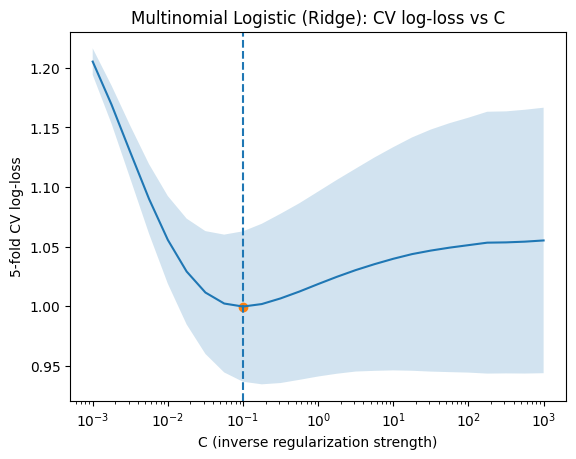

Multinomial best C: 0.1 best CV log-loss: 0.9996685261305597


In [315]:
# --- Multinomial ---
multi_results = pd.DataFrame(multi_search.cv_results_).copy()
multi_results["C"] = multi_results["param_model__C"].astype(float)
multi_results["mean_logloss"] = -multi_results["mean_test_score"]
multi_results["std_logloss"]  = multi_results["std_test_score"].abs()

multi_results = multi_results.sort_values("C")

best_C_multi = multi_search.best_params_["model__C"]
best_loss_multi = -multi_search.best_score_

plt.figure()
plt.semilogx(multi_results["C"], multi_results["mean_logloss"])
plt.fill_between(
    multi_results["C"],
    multi_results["mean_logloss"] - multi_results["std_logloss"],
    multi_results["mean_logloss"] + multi_results["std_logloss"],
    alpha=0.2
)
plt.axvline(best_C_multi, linestyle="--")
plt.scatter([best_C_multi], [best_loss_multi])
plt.xlabel("C (inverse regularization strength)")
plt.ylabel("5-fold CV log-loss")
plt.title("Multinomial Logistic (Ridge): CV log-loss vs C")
plt.show()

print("Multinomial best C:", best_C_multi, "best CV log-loss:", best_loss_multi)

# Binary Jackknife


Jackknife SE for Binary logistic MLE coefficients

In [316]:
n = X_sm.shape[0]
param_names = logit_res.params.index

theta_full = logit_res.params.copy()

# Store leave-one-out params
theta_loo = np.zeros((n, len(param_names)))

failed = 0
for i in range(n):
    # Leave out i
    X_i = X_sm.drop(index=X_sm.index[i])
    y_i = np.delete(y_bin, i)

    try:
        res_i = sm.Logit(y_i, X_i).fit(disp=False)
        theta_loo[i, :] = res_i.params.values
    except Exception:
        # If a refit fails (rare but possible), mark as NaN and count
        theta_loo[i, :] = np.nan
        failed += 1

theta_loo_df = pd.DataFrame(theta_loo, columns=param_names)

print("Jackknife refits failed:", failed)

# Drop failed rows if any
theta_loo_df = theta_loo_df.dropna(axis=0)
m = theta_loo_df.shape[0]   # effective number of successful jackknife fits

# Jackknife mean across leave-one-out fits
theta_bar = theta_loo_df.mean(axis=0)

# Jackknife variance and SE (use m instead of n if some failed)
jack_var = ((m - 1) / m) * ((theta_loo_df - theta_bar)**2).sum(axis=0)
jack_se = np.sqrt(jack_var)

# Compare to asymptotic SE from full MLE
asym_se = logit_res.bse

se_compare = pd.DataFrame({
    "coef_full_MLE": theta_full,
    "asym_se": asym_se,
    "jack_se": jack_se,
    "jack_over_asym": jack_se / asym_se
}).sort_values("jack_over_asym", ascending=False)

se_compare

Jackknife refits failed: 0


,coef_full_MLE,asym_se,jack_se,jack_over_asym
cp_4.0,1.431577,0.440324,0.528521,1.200301
trestbps,0.114464,0.106307,0.127131,1.195884
cp_3.0,-0.014581,0.452003,0.535102,1.183847
cp_2.0,-0.418834,0.487646,0.570695,1.170305
chol,-0.181738,0.109006,0.125788,1.153957
const,-2.056124,0.476069,0.536830,1.127629
restecg_1.0,-0.078208,0.302903,0.338654,1.118029
oldpeak,0.682858,0.124555,0.131075,1.052348
fbs_1.0,0.526597,0.292557,0.307266,1.050276
sex_1.0,1.299613,0.256907,0.266864,1.038758


### jackknife for ridge logreg

In [317]:
# Ensure X_ridge is numpy array but keep names from X_sm
X_mat = np.asarray(X_ridge)     # (n, p) numpy array
y_vec = np.asarray(y_bin)
n, p = X_mat.shape

param_names = X_sm.columns.drop("const")  # adjust if ridge excludes const
C_best_bin = 0.31622776601683794

# ---- Full ridge fit ----
ridge_full = LogisticRegression(
    penalty="l2",
    C=C_best_bin,
    solver="lbfgs",
    max_iter=5000,
    fit_intercept=False
)

ridge_full.fit(X_mat, y_vec)
coef_full_ridge = ridge_full.coef_.ravel()

# ---- Jackknife storage ----
coef_loo = np.zeros((n, p))
failed = 0

for i in range(n):

    mask = np.ones(n, dtype=bool)
    mask[i] = False

    X_i = X_mat[mask, :]
    y_i = y_vec[mask]

    try:
        m_i = LogisticRegression(
            penalty="l2",
            C=C_best_bin,
            solver="lbfgs",
            max_iter=5000,
            fit_intercept=False
        )
        m_i.fit(X_i, y_i)
        coef_loo[i, :] = m_i.coef_.ravel()

    except Exception:
        coef_loo[i, :] = np.nan
        failed += 1

print("Ridge jackknife refits failed:", failed)

# Drop failed rows
coef_loo = coef_loo[~np.isnan(coef_loo).any(axis=1)]
m = coef_loo.shape[0]

# ---- Jackknife SE ----
coef_bar = coef_loo.mean(axis=0)
jack_var = ((m - 1) / m) * np.sum((coef_loo - coef_bar)**2, axis=0)
jack_se_ridge = np.sqrt(jack_var)

# ---- Comparable output table ----
ridge_compare = pd.DataFrame({
    "coef_full_ridge": coef_full_ridge,
    "jack_se_ridge": jack_se_ridge
}, index=param_names)

ridge_compare["abs_coef"] = np.abs(ridge_compare["coef_full_ridge"])
ridge_compare = ridge_compare.sort_values("jack_se_ridge", ascending=False)

ridge_compare

Ridge jackknife refits failed: 0


,coef_full_ridge,jack_se_ridge,abs_coef
restecg_1.0,-0.190983,0.232200,0.190983
fbs_1.0,0.305267,0.222780,0.305267
restecg_2.0,-0.041763,0.200113,0.041763
cp_2.0,-1.434997,0.197531,1.434997
cp_3.0,-1.116285,0.190359,1.116285
exang_1.0,0.766392,0.190233,0.766392
cp_4.0,0.189896,0.189759,0.189896
sex_1.0,0.511809,0.169960,0.511809
oldpeak,0.687618,0.116972,0.687618
trestbps,0.096516,0.108054,0.096516


In [318]:
comparison = se_compare.join(
    ridge_compare[["coef_full_ridge", "jack_se_ridge"]],
    how="inner"
)

comparison["ridge_over_mle_jack"] = (
    comparison["jack_se_ridge"] / comparison["jack_se"]
)

comparison.sort_values("ridge_over_mle_jack")

,coef_full_MLE,asym_se,jack_se,jack_over_asym,coef_full_ridge,jack_se_ridge,ridge_over_mle_jack
cp_2.0,-0.418834,0.487646,0.570695,1.170305,-1.434997,0.197531,0.346124
cp_3.0,-0.014581,0.452003,0.535102,1.183847,-1.116285,0.190359,0.355744
cp_4.0,1.431577,0.440324,0.528521,1.200301,0.189896,0.189759,0.359038
sex_1.0,1.299613,0.256907,0.266864,1.038758,0.511809,0.169960,0.636878
restecg_1.0,-0.078208,0.302903,0.338654,1.118029,-0.190983,0.232200,0.685654
fbs_1.0,0.526597,0.292557,0.307266,1.050276,0.305267,0.222780,0.725040
restecg_2.0,0.256040,0.253436,0.258522,1.020070,-0.041763,0.200113,0.774065
exang_1.0,1.008121,0.231108,0.236970,1.025362,0.766392,0.190233,0.802775
trestbps,0.114464,0.106307,0.127131,1.195884,0.096516,0.108054,0.849947
chol,-0.181738,0.109006,0.125788,1.153957,-0.212268,0.107228,0.852446


Jackknife SE for a predicted probability

In [319]:
# Choose a reference x0 (mean feature vector, keeps const=1)
x0 = X_sm.mean(axis=0).values.reshape(1, -1)

# Predicted probability on full model
p_full = float(logit_res.predict(x0))

# Predicted probabilities for each leave-one-out refit
p_loo = []
for i in range(theta_loo_df.shape[0]):
    beta_i = theta_loo_df.iloc[i].values.reshape(-1, 1)
    # logistic p = 1 / (1 + exp(-x beta))
    p = 1.0 / (1.0 + np.exp(-(x0 @ beta_i)))
    p_loo.append(float(p))

p_loo = np.array(p_loo)

p_bar = p_loo.mean()
p_jack_var = ((len(p_loo)-1)/len(p_loo)) * np.sum((p_loo - p_bar)**2)
p_jack_se = np.sqrt(p_jack_var)

print("p_full:", p_full)
print("jackknife SE for p(x0):", p_jack_se)

p_full: 0.5345169565997965
jackknife SE for p(x0): 0.026227436036028333


C:\Users\abels\AppData\Local\Temp\ipykernel_14076\3583788587.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  p_full = float(logit_res.predict(x0))
C:\Users\abels\AppData\Local\Temp\ipykernel_14076\3583788587.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  p_loo.append(float(p))


ridge

In [320]:
# Make sure this is the same matrix you used for ridge fitting (likely no const column)
X_mat = np.asarray(X_ridge)
y_vec = np.asarray(y_bin)
n, p = X_mat.shape

# Choose x0 = mean feature vector (NO const unless it's actually in X_ridge)
x0 = X_mat.mean(axis=0).reshape(1, -1)

C_best_bin = 0.31622776601683794

# --- Full ridge fit ---
ridge_full = LogisticRegression(
    penalty="l2",
    C=C_best_bin,
    solver="lbfgs",
    max_iter=5000,
    fit_intercept=False
)
ridge_full.fit(X_mat, y_vec)

# Predicted probability on full ridge model
p_full = ridge_full.predict_proba(x0)[0, 1]

# --- Predicted probabilities for each LOO ridge refit ---
# If you already computed coef_loo (after dropping failed rows), use it directly:
# coef_loo shape should be (m, p)
p_loo = []
for j in range(coef_loo.shape[0]):
    beta_j = coef_loo[j, :].reshape(-1, 1)            # (p, 1)
    eta = float(x0 @ beta_j)                           # scalar
    p = 1.0 / (1.0 + np.exp(-eta))                     # logistic link
    p_loo.append(p)

p_loo = np.asarray(p_loo)

# Jackknife SE for p(x0)
p_bar = p_loo.mean()
m = len(p_loo)
p_jack_var = ((m - 1) / m) * np.sum((p_loo - p_bar) ** 2)
p_jack_se = np.sqrt(p_jack_var)

print("ridge p_full:", p_full)
print("ridge jackknife SE for p(x0):", p_jack_se)

ridge p_full: 0.5670470855637445
ridge jackknife SE for p(x0): 0.02217485346713859


C:\Users\abels\AppData\Local\Temp\ipykernel_14076\14389540.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  eta = float(x0 @ beta_j)                           # scalar


# Multinomial Jackknife


### jackknife Multinomial MLE 

In [321]:
Xj = X_sm.reset_index(drop=True)
yj = np.asarray(y_multi)
n  = Xj.shape[0]

# --- model config ---
# MLE multinomial (no ridge). If your sklearn complains about "none", try penalty=None.
base_model_kwargs = dict(
    penalty=None,
    solver="lbfgs",
    fit_intercept=False,
    max_iter=5000
)

# Full fit
lr_full = LogisticRegression(**base_model_kwargs)
lr_full.fit(Xj.values, yj)

# sklearn coef_ shape is (n_classes, n_features)
classes = lr_full.classes_
feat_names = Xj.columns
coef_full = lr_full.coef_  # (K, p)

# We'll store LOOCV coefs in shape (n, K, p) to mirror your (n, n_eq, n_params)-like structure
K = len(classes)
p = Xj.shape[1]
theta_loo = np.full((n, K, p), np.nan)

failed = 0
for i in range(n):
    mask = np.ones(n, dtype=bool)
    mask[i] = False

    X_i = Xj.values[mask, :]
    y_i = yj[mask]

    try:
        lr_i = LogisticRegression(**base_model_kwargs)
        lr_i.fit(X_i, y_i)

        # Important: ensure class order matches the full fit
        # If a class disappears in a leave-one-out split, coef_ will have fewer rows.
        coef_i = np.full((K, p), np.nan)

        cls_i = lr_i.classes_
        for r, c in enumerate(cls_i):
            idx = np.where(classes == c)[0][0]
            coef_i[idx, :] = lr_i.coef_[r, :]

        theta_loo[i, :, :] = coef_i

    except Exception as e:
        failed += 1
        if failed == 1:
            print("First LogisticRegression jackknife failure at i =", i, "error:", repr(e))

print("LogisticRegression jackknife refits failed:", failed)

# Keep only successful refits AND those without missing classes
valid = ~np.isnan(theta_loo).any(axis=(1, 2))
theta_loo_valid = theta_loo[valid, :, :]
m = theta_loo_valid.shape[0]

# Jackknife mean: (K, p)
theta_bar = theta_loo_valid.mean(axis=0)

# Jackknife variance per (class, feature): (K, p)
jack_var = ((m - 1) / m) * np.sum((theta_loo_valid - theta_bar) ** 2, axis=0)
jack_se  = np.sqrt(jack_var)

# Output as a tidy DataFrame similar to your statsmodels output:
# rows = features, cols = classes (or "equations")
jack_se_df = pd.DataFrame(jack_se.T, index=feat_names, columns=classes)
jack_se_df

LogisticRegression jackknife refits failed: 0


,0,1,2,3,4
const,1.138830,1.157611,1.220098,1.316271,4.058419
age,0.132509,0.125745,0.152320,0.161784,0.347049
trestbps,0.126060,0.098251,0.104919,0.142438,0.241545
chol,0.118487,0.099565,0.116388,0.118616,0.226878
thalach,0.131903,0.117886,0.153949,0.166975,0.335171
oldpeak,0.126729,0.096714,0.114198,0.134560,0.222811
sex_1.0,0.380987,0.379882,0.492302,0.463776,1.256421
cp_2.0,0.614805,0.648992,1.075712,1.112882,0.792535
cp_3.0,1.019313,1.040649,1.053718,1.209150,3.501637
cp_4.0,1.020445,1.028565,1.018028,1.196293,3.485334


### jackknife multinomial ridge 

In [322]:
Xj = X_sm.reset_index(drop=True)
yj = np.asarray(y_multi)
n  = Xj.shape[0]

# --- model config ---
# MLE multinomial (no ridge). If your sklearn complains about "none", try penalty=None.
base_model_kwargs = dict(
    penalty="l2",
    solver="lbfgs",
    fit_intercept=False,
    max_iter=5000,
    C=1.0
)

# Full fit
lr_full = LogisticRegression(**base_model_kwargs)
lr_full.fit(Xj.values, yj)

# sklearn coef_ shape is (n_classes, n_features)
classes = lr_full.classes_
feat_names = Xj.columns
coef_full = lr_full.coef_  # (K, p)

# We'll store LOOCV coefs in shape (n, K, p) to mirror your (n, n_eq, n_params)-like structure
K = len(classes)
p = Xj.shape[1]
theta_loo = np.full((n, K, p), np.nan)

failed = 0
for i in range(n):
    mask = np.ones(n, dtype=bool)
    mask[i] = False

    X_i = Xj.values[mask, :]
    y_i = yj[mask]

    try:
        lr_i = LogisticRegression(**base_model_kwargs)
        lr_i.fit(X_i, y_i)

        # Important: ensure class order matches the full fit
        # If a class disappears in a leave-one-out split, coef_ will have fewer rows.
        coef_i = np.full((K, p), np.nan)

        cls_i = lr_i.classes_
        for r, c in enumerate(cls_i):
            idx = np.where(classes == c)[0][0]
            coef_i[idx, :] = lr_i.coef_[r, :]

        theta_loo[i, :, :] = coef_i

    except Exception as e:
        failed += 1
        if failed == 1:
            print("First LogisticRegression jackknife failure at i =", i, "error:", repr(e))

print("Ridge LogisticRegression jackknife refits failed:", failed)

# Keep only successful refits AND those without missing classes
valid = ~np.isnan(theta_loo).any(axis=(1, 2))
theta_loo_valid = theta_loo[valid, :, :]
m = theta_loo_valid.shape[0]

# Jackknife mean: (K, p)
theta_bar = theta_loo_valid.mean(axis=0)

# Jackknife variance per (class, feature): (K, p)
jack_var = ((m - 1) / m) * np.sum((theta_loo_valid - theta_bar) ** 2, axis=0)
jack_se  = np.sqrt(jack_var)

# Output as a tidy DataFrame similar to your statsmodels output:
# rows = features, cols = classes (or "equations")
jack_ridge_se_df = pd.DataFrame(jack_se.T, index=feat_names, columns=classes)
jack_ridge_se_df

Ridge LogisticRegression jackknife refits failed: 0


,0,1,2,3,4
const,0.286092,0.272113,0.289779,0.267878,0.321914
age,0.108790,0.105121,0.133727,0.142415,0.248665
trestbps,0.109733,0.087173,0.095288,0.133852,0.181889
chol,0.105182,0.090842,0.109677,0.110168,0.185010
thalach,0.110593,0.100386,0.136657,0.147544,0.240574
oldpeak,0.114966,0.089325,0.107896,0.126232,0.187227
sex_1.0,0.193944,0.203369,0.281757,0.279215,0.330439
cp_2.0,0.304159,0.321340,0.401135,0.460850,0.118524
cp_3.0,0.297558,0.300167,0.320280,0.301372,0.389060
cp_4.0,0.290931,0.262610,0.265676,0.267337,0.333370


only high values (standard multinomial)

Multinomial prediction errors


In [323]:
def softmax(scores: np.ndarray) -> np.ndarray:
    """Numerically stable softmax for shape (K,) or (1,K)."""
    s = scores - np.max(scores, axis=-1, keepdims=True)
    ex = np.exp(s)
    return ex / np.sum(ex, axis=-1, keepdims=True)

def multinomial_jackknife_pred_se(
    Xj: pd.DataFrame,
    yj: np.ndarray,
    base_model_kwargs: dict,
    x0: np.ndarray | None = None
):
    """
    Fits multinomial LogisticRegression on full data and LOO refits.
    Returns:
      - p_full: Series of predicted probs at x0 (one per class)
      - p_jack_se: Series of jackknife SE of probs at x0 (one per class)
      - theta_loo_valid: array of LOO coefs (m, K, p)
      - classes: array of class labels (K,)
    """
    X = Xj.values
    y = np.asarray(yj)
    n, p = X.shape

    # Reference x0
    if x0 is None:
        x0 = X.mean(axis=0, keepdims=True)  # (1,p)
    else:
        x0 = np.asarray(x0).reshape(1, -1)

    # ---- Full fit ----
    lr_full = LogisticRegression(**base_model_kwargs)
    lr_full.fit(X, y)
    classes = lr_full.classes_
    K = len(classes)

    # Full predicted probability at x0
    p_full = lr_full.predict_proba(x0).ravel()  # (K,)

    # ---- LOO coefficient storage ----
    theta_loo = np.full((n, K, p), np.nan)
    failed = 0

    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False

        X_i = X[mask, :]
        y_i = y[mask]

        try:
            lr_i = LogisticRegression(**base_model_kwargs)
            lr_i.fit(X_i, y_i)

            # Align class rows to full-fit ordering
            coef_i = np.full((K, p), np.nan)
            for r, c in enumerate(lr_i.classes_):
                idx = np.where(classes == c)[0][0]
                coef_i[idx, :] = lr_i.coef_[r, :]

            theta_loo[i, :, :] = coef_i

        except Exception as e:
            failed += 1
            if failed == 1:
                print("First multinomial jackknife failure at i =", i, "error:", repr(e))

    print("Multinomial jackknife refits failed:", failed)

    # Keep only successful refits (and those where all classes exist)
    valid = ~np.isnan(theta_loo).any(axis=(1, 2))
    theta_loo_valid = theta_loo[valid, :, :]
    m = theta_loo_valid.shape[0]

    # ---- Compute p_loo(x0) from each refit ----
    # scores_j = x0 @ coef_j^T  -> (1,K)
    # p_j = softmax(scores_j)
    p_loo = np.zeros((m, K))
    for j in range(m):
        coef_j = theta_loo_valid[j, :, :]          # (K,p)
        scores = x0 @ coef_j.T                     # (1,K)
        p_loo[j, :] = softmax(scores).ravel()      # (K,)

    # ---- Jackknife SE per class probability ----
    p_bar = p_loo.mean(axis=0)                     # (K,)
    p_jack_var = ((m - 1) / m) * np.sum((p_loo - p_bar) ** 2, axis=0)
    p_jack_se = np.sqrt(p_jack_var)

    p_full_s = pd.Series(p_full, index=classes, name="p_full")
    p_se_s   = pd.Series(p_jack_se, index=classes, name="jack_se_p")

    return p_full_s, p_se_s, theta_loo_valid, classes

no penalty

In [324]:
Xj = X_sm.reset_index(drop=True)
yj = np.asarray(y_multi)

kwargs_mle_multi = dict(
    penalty=None,              # or "none" depending on sklearn version
    solver="lbfgs",
    fit_intercept=False,
    max_iter=5000
)

p_full_mle, p_se_mle, theta_valid_mle, classes = multinomial_jackknife_pred_se(
    Xj, yj, kwargs_mle_multi
)

pd.concat([p_full_mle, p_se_mle], axis=1)

Multinomial jackknife refits failed: 0


,p_full,jack_se_p
0,0.502575,0.028123
1,0.352005,0.027378
2,0.081743,0.018416
3,0.058039,0.015189
4,0.005638,0.005614


penalty

In [325]:
kwargs_ridge_multi = dict(
    penalty="l2",
    C=1.0,                     # set your chosen C here
    solver="lbfgs",
    fit_intercept=False,
    max_iter=5000
)

p_full_ridge, p_se_ridge, theta_valid_ridge, classes = multinomial_jackknife_pred_se(
    Xj, yj, kwargs_ridge_multi
)

pd.concat([p_full_ridge, p_se_ridge], axis=1)

Multinomial jackknife refits failed: 0


,p_full,jack_se_p
0,0.493396,0.026812
1,0.339615,0.025035
2,0.086742,0.013590
3,0.063517,0.013224
4,0.016729,0.004479


In [326]:
compare_probs = pd.concat([
    p_full_mle.rename("p_full_mle"),
    p_se_mle.rename("p_se_mle"),
    p_full_ridge.rename("p_full_ridge"),
    p_se_ridge.rename("p_se_ridge"),
], axis=1)

compare_probs["ridge_over_mle_se"] = compare_probs["p_se_ridge"] / compare_probs["p_se_mle"]
compare_probs

,p_full_mle,p_se_mle,p_full_ridge,p_se_ridge,ridge_over_mle_se
0,0.502575,0.028123,0.493396,0.026812,0.953380
1,0.352005,0.027378,0.339615,0.025035,0.914401
2,0.081743,0.018416,0.086742,0.013590,0.737973
3,0.058039,0.015189,0.063517,0.013224,0.870646
4,0.005638,0.005614,0.016729,0.004479,0.797924


In [328]:
df_full

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num,origin,target
0,48.0,1.0,4.0,130.0,256.0,1.0,2.0,150.0,1.0,0.0,3,CLE,1
1,53.0,0.0,2.0,140.0,216.0,0.0,0.0,142.0,1.0,2.0,0,HUN,0
2,39.0,1.0,2.0,190.0,241.0,0.0,0.0,106.0,0.0,0.0,0,HUN,0
3,42.0,0.0,3.0,115.0,211.0,0.0,1.0,137.0,0.0,0.0,0,HUN,0
4,52.0,1.0,2.0,120.0,284.0,0.0,0.0,118.0,0.0,0.0,0,HUN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,67.0,1.0,4.0,125.0,254.0,1.0,0.0,163.0,0.0,0.2,3,CLE,1
736,59.0,1.0,4.0,140.0,177.0,0.0,0.0,162.0,1.0,0.0,2,CLE,1
737,61.0,1.0,4.0,140.0,207.0,0.0,2.0,138.0,1.0,1.9,1,CLE,1
738,54.0,1.0,3.0,120.0,217.0,0.0,0.0,137.0,0.0,0.0,0,HUN,0


In [329]:
def summarize_df_for_report(
    df_full: pd.DataFrame,
    target_col: str,
    continuous_cols: list[str] | None = None,
    categorical_cols: list[str] | None = None,
    top_k_levels: int = 5,
) -> dict:
    df = df_full.copy()

    # Basic shape
    n, p = df.shape
    summary = {
        "n_rows": n,
        "n_cols_total": p,
        "target_col": target_col,
    }

    # If user didn't specify columns, infer types
    if continuous_cols is None:
        continuous_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        if target_col in continuous_cols:
            continuous_cols.remove(target_col)

    if categorical_cols is None:
        # treat non-numeric as categorical, plus numeric with few unique values
        cat1 = df.select_dtypes(exclude=[np.number]).columns.tolist()
        cat2 = [c for c in df.columns
                if c != target_col and c not in continuous_cols and df[c].nunique(dropna=True) <= 10]
        categorical_cols = sorted(set(cat1 + cat2))

    summary["continuous_cols"] = continuous_cols
    summary["categorical_cols"] = categorical_cols

    # Target distribution (counts + pct)
    y = df[target_col]
    target_counts = y.value_counts(dropna=False).sort_index()
    target_pct = (target_counts / len(y) * 100).round(1)

    target_dist = pd.DataFrame({
        "count": target_counts.astype(int),
        "pct": target_pct
    })
    summary["target_distribution"] = target_dist

    # Continuous summary
    if continuous_cols:
        cont = df[continuous_cols]
        cont_summary = cont.agg(["mean", "std", "min", "max"]).T
        cont_summary = cont_summary.round(3)
        summary["continuous_summary"] = cont_summary
    else:
        summary["continuous_summary"] = pd.DataFrame()

    # Categorical summary (top-k levels)
    cat_summaries = {}
    for c in categorical_cols:
        vc = df[c].value_counts(dropna=False)
        top = vc.head(top_k_levels)
        cat_summaries[c] = pd.DataFrame({
            "level": top.index.astype(str),
            "count": top.values,
            "pct": (top.values / len(df) * 100).round(1),
        })
    summary["categorical_top_levels"] = cat_summaries

    return summary


# ---- USAGE ----
# Set this to your actual outcome column name (e.g., "target" or "num" etc.)
TARGET_COL = "YOUR_TARGET_COLUMN"

summary = summarize_df_for_report(df_full, target_col="num")

print("n_rows:", summary["n_rows"])
print("n_cols_total:", summary["n_cols_total"])
print("\nTarget distribution:")
print(summary["target_distribution"])

print("\nContinuous summary (first 10 rows):")
print(summary["continuous_summary"])

# Example: show one categorical column's top levels
if summary["categorical_cols"]:
    example_col = summary["categorical_cols"][0]
    print(f"\nTop levels for {example_col}:")
    print(summary["categorical_top_levels"][example_col])

n_rows: 740
n_cols_total: 13

Target distribution:
     count   pct
num             
0      357  48.2
1      204  27.6
2       79  10.7
3       78  10.5
4       22   3.0

Continuous summary (first 10 rows):
             mean     std   min    max
age        53.097   9.408  28.0   77.0
sex         0.765   0.424   0.0    1.0
cp          3.227   0.939   1.0    4.0
trestbps  132.754  18.581   0.0  200.0
chol      220.136  93.615   0.0  603.0
fbs         0.150   0.357   0.0    1.0
restecg     0.635   0.840   0.0    2.0
thalach   138.745  25.846  60.0  202.0
exang       0.400   0.490   0.0    1.0
oldpeak     0.894   1.087  -1.0    6.2
target      0.518   0.500   0.0    1.0

Top levels for origin:
  level  count   pct
0   CLE    303  40.9
1   HUN    261  35.3
2    VA    130  17.6
3    SW     46   6.2


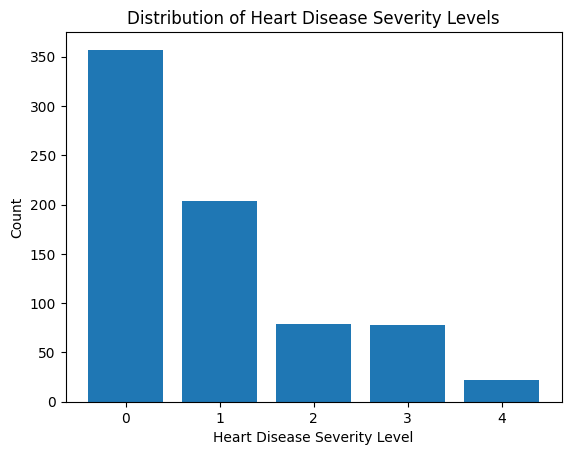

In [330]:
# Ensure the outcome column name matches your dataset
outcome_col = "num"

# Compute counts
counts = df_full[outcome_col].value_counts().sort_index()

# Create plot (single plot, no specific colors)
plt.figure()
plt.bar(counts.index.astype(str), counts.values)
plt.xlabel("Heart Disease Severity Level")
plt.ylabel("Count")
plt.title("Distribution of Heart Disease Severity Levels")
plt.show()